# Part A — Data Preparation & Exam Score Prediction

## Step 1: Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                               RandomForestClassifier, IsolationForest)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                              classification_report, confusion_matrix, roc_auc_score)

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# Boosting libraries — pehli dafa run kar rahe hain to install kar lein
!pip install xgboost catboost lightgbm -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00


## Step 2: Dataset Load Karna
`StudentPerformanceFactors.csv` ko Colab Files panel me upload karein, phir yeh cell chalayen.


In [4]:
# df = pd.read_csv('StudentPerformanceFactors.csv')
# print(df.shape)
# df.head()


In [5]:
from google.colab import drive
drive.mount('/content/drive')

# Google Drive se CSV file load karna
df = pd.read_csv('/content/drive/MyDrive/Ai_PrimerCourse/ColabDataSet/StudentPerformanceFactors.csv')

# Rows aur Columns ka count (shape) print karna
print(df.shape)

# Pehli 5 rows dekhna
df.head()

Mounted at /content/drive
(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## Step 3: Missing Values Handle Karna

In [6]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("Missing % per column:\n", missing_percentage[missing_percentage > 0])

drop_columns = missing_percentage[missing_percentage > 20].keys()
df = df.drop(columns=drop_columns)
print("\nDropped columns (>20% missing):", list(drop_columns))

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if not pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

print("\nTotal missing values after cleaning:", df.isnull().sum().sum())


Missing % per column:
 Teacher_Quality             1.180566
Parental_Education_Level    1.362192
Distance_from_Home          1.014076
dtype: float64

Dropped columns (>20% missing): []

Total missing values after cleaning: 0


## Step 4: Categorical Encoding
Original (raw) categorical columns ko hum **naye names** me copy kar ke rakh lete hain (dashboard/alerts ke liye readable form chahiye hogi), phir encoding karte hain model training ke liye.


In [7]:
df_raw = df.copy()   # readable version — dashboard & alerts ke liye use hoga

ordinal_map_lmh = {'Low': 0, 'Medium': 1, 'High': 2}
distance_map = {'Near': 0, 'Moderate': 1, 'Far': 2}

for col in ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
            'Family_Income', 'Teacher_Quality']:
    if col in df.columns:
        df[col] = df[col].map(ordinal_map_lmh)

if 'Distance_from_Home' in df.columns:
    df['Distance_from_Home'] = df['Distance_from_Home'].map(distance_map)

nominal_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

print("Final feature set shape:", df.shape)
df.head()


Final feature set shape: (6607, 22)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Family_Income,Teacher_Quality,...,Exam_Score,Extracurricular_Activities_Yes,Internet_Access_Yes,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Gender_Male
0,23,84,0,2,7,73,0,0,0,1,...,67,False,True,True,False,True,False,True,False,True
1,19,64,0,1,8,59,0,2,1,1,...,61,False,True,True,False,False,False,False,False,False
2,24,98,1,1,7,91,1,2,1,1,...,74,True,True,True,True,False,False,False,True,True
3,29,89,0,1,8,98,1,1,1,1,...,71,True,True,True,False,False,False,True,False,True
4,19,92,1,1,6,65,1,3,1,2,...,70,True,True,True,True,False,False,False,False,False


## Step 5: Correlation Heatmap (EDA)

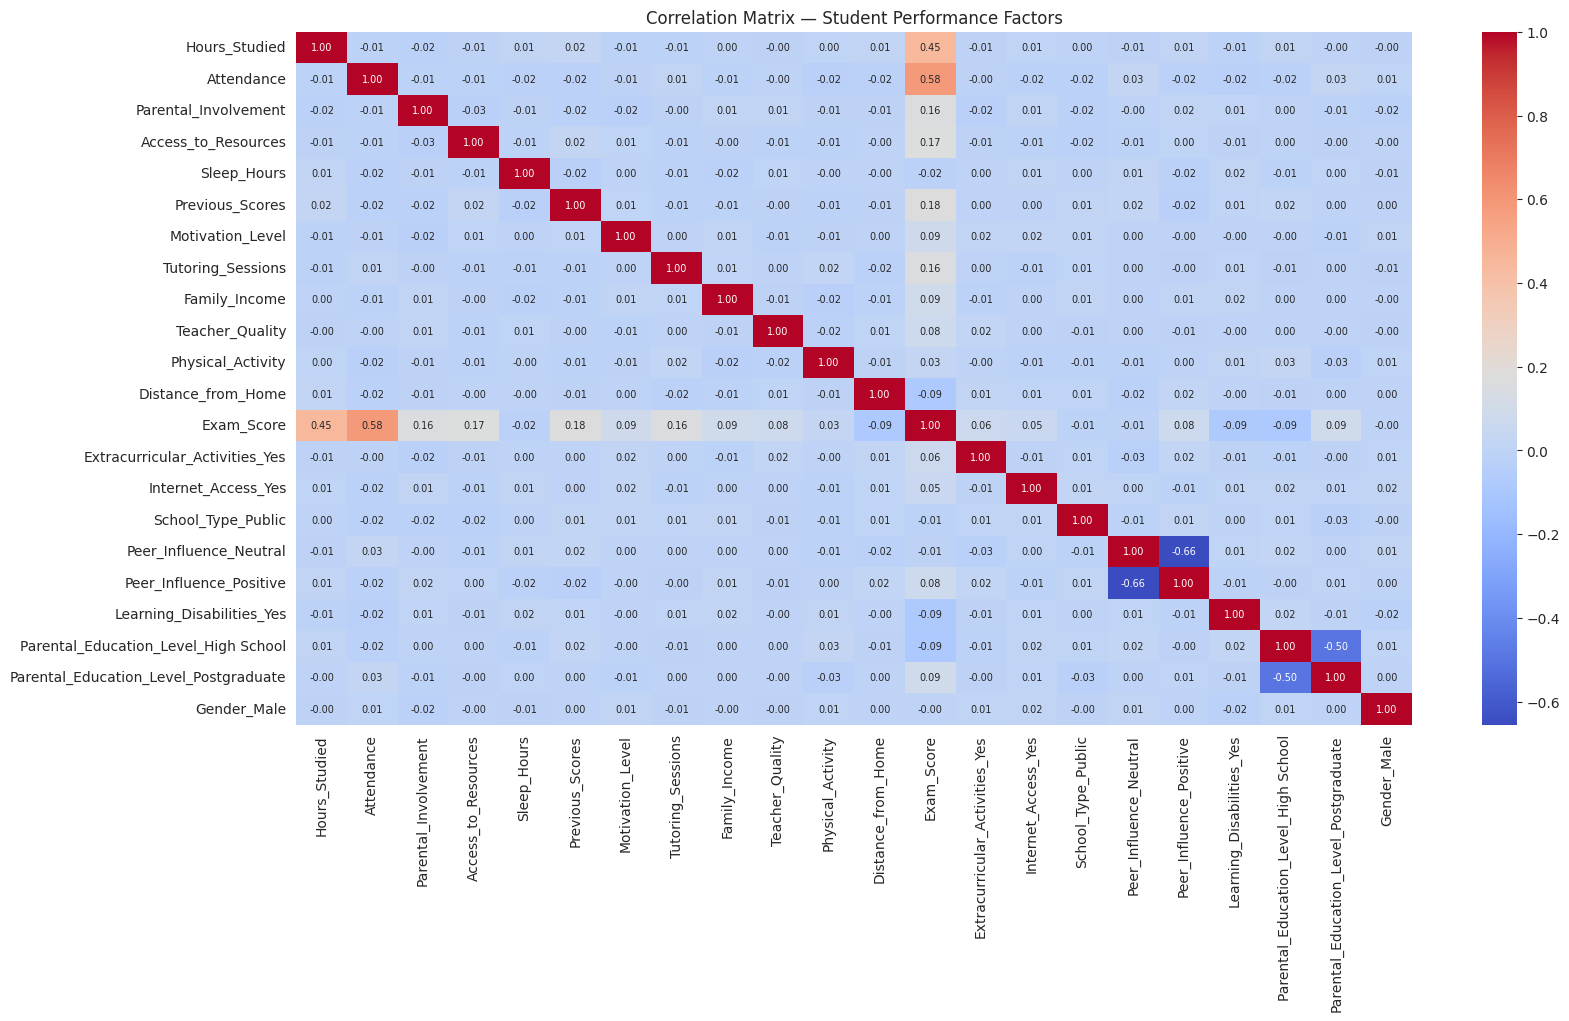


Top features correlated with Exam_Score:
Exam_Score                               1.000000
Attendance                               0.581072
Hours_Studied                            0.445455
Previous_Scores                          0.175079
Access_to_Resources                      0.169770
Parental_Involvement                     0.157114
Tutoring_Sessions                        0.156525
Family_Income                            0.094555
Parental_Education_Level_Postgraduate    0.093764
Motivation_Level                         0.086937
Name: Exam_Score, dtype: float64


In [8]:
plt.figure(figsize=(18, 9))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', annot_kws={'size':7})
plt.title('Correlation Matrix — Student Performance Factors')
plt.show()

print("\nTop features correlated with Exam_Score:")
print(corr_matrix['Exam_Score'].sort_values(ascending=False).head(10))


## Step 6: Features/Target Split & Train-Test Split

In [9]:
X = df.drop('Exam_Score', axis=1)
y = df['Exam_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, " X_test:", X_test.shape)


X_train: (5285, 21)  X_test: (1322, 21)


## Step 7: Reusable Evaluation Function

In [10]:
results = []

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    y_pred = model.predict(X_te)
    y_train_pred = model.predict(X_tr)

    mae = mean_absolute_error(y_te, y_pred)
    mse = mean_squared_error(y_te, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_te, y_pred)
    r2_train = r2_score(y_tr, y_train_pred)
    relative_rmse = (rmse / np.mean(y_te)) * 100

    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2_Test': r2,
                     'R2_Train': r2_train, 'Relative_RMSE_%': relative_rmse})

    print(f"--- {name} ---")
    print(f"MAE: {mae:.3f} | RMSE: {rmse:.3f} | Relative RMSE: {relative_rmse:.2f}%")
    print(f"R2 Train: {r2_train:.4f} | R2 Test: {r2:.4f}")
    return y_pred


## Step 8: Linear Regression

In [11]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = evaluate_model('Linear Regression', lr, X_train, X_test, y_train, y_test)


--- Linear Regression ---
MAE: 0.445 | RMSE: 1.800 | Relative RMSE: 2.67%
R2 Train: 0.7170 | R2 Test: 0.7707


## Step 9: Lasso & Ridge

In [12]:
lasso = Lasso(alpha=0.1).fit(X_train, y_train)
_ = evaluate_model('Lasso', lasso, X_train, X_test, y_train, y_test)

ridge = Ridge(alpha=1.0).fit(X_train, y_train)
_ = evaluate_model('Ridge', ridge, X_train, X_test, y_train, y_test)


--- Lasso ---
MAE: 0.711 | RMSE: 1.892 | Relative RMSE: 2.81%
R2 Train: 0.6856 | R2 Test: 0.7468
--- Ridge ---
MAE: 0.445 | RMSE: 1.800 | Relative RMSE: 2.67%
R2 Train: 0.7170 | R2 Test: 0.7707


## Step 10: Polynomial Regression (degree=2)

In [13]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

lr_poly = LinearRegression().fit(X_train_poly, y_train)
_ = evaluate_model('Polynomial Regression', lr_poly, X_train_poly, X_test_poly, y_train, y_test)


--- Polynomial Regression ---
MAE: 0.574 | RMSE: 1.859 | Relative RMSE: 2.76%
R2 Train: 0.7301 | R2 Test: 0.7556


## Step 11: SVR (multiple kernels) + Tuning

In [14]:
for kernel in ['rbf', 'linear', 'poly', 'sigmoid']:
    svr = SVR(kernel=kernel).fit(X_train, y_train)
    _ = evaluate_model(f'SVR ({kernel})', svr, X_train, X_test, y_train, y_test)


--- SVR (rbf) ---
MAE: 1.104 | RMSE: 2.125 | Relative RMSE: 3.16%
R2 Train: 0.6187 | R2 Test: 0.6806
--- SVR (linear) ---
MAE: 0.406 | RMSE: 1.800 | Relative RMSE: 2.67%
R2 Train: 0.7140 | R2 Test: 0.7707
--- SVR (poly) ---
MAE: 0.972 | RMSE: 2.026 | Relative RMSE: 3.01%
R2 Train: 0.6449 | R2 Test: 0.7095
--- SVR (sigmoid) ---
MAE: 14.692 | RMSE: 18.068 | Relative RMSE: 26.84%
R2 Train: -20.3531 | R2 Test: -22.0950


In [15]:
param_grid = {'kernel': ['rbf'], 'C': [1, 10], 'epsilon': [0.1], 'gamma': ['scale']}
grid_search = GridSearchCV(SVR(), param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)
best_svr = grid_search.best_estimator_
_ = evaluate_model('SVR (Tuned)', best_svr, X_train, X_test, y_train, y_test)


--- SVR (Tuned) ---
MAE: 0.470 | RMSE: 1.809 | Relative RMSE: 2.69%
R2 Train: 0.7084 | R2 Test: 0.7685


## Step 12: Decision Tree (+ Tuning)

In [16]:
dt_model = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, y_train)
_ = evaluate_model('Decision Tree', dt_model, X_train, X_test, y_train, y_test)

param_dist = {"max_depth": [3,5,10,15,None], "min_samples_split": [2,5,10,20],
              "min_samples_leaf": [1,2,5,10], "max_features": ["sqrt","log2",None]}
random_search = RandomizedSearchCV(DecisionTreeRegressor(random_state=42), param_dist, n_iter=10,
                                    cv=3, scoring="neg_mean_squared_error", n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)
best_dt = random_search.best_estimator_
_ = evaluate_model('Decision Tree (Tuned)', best_dt, X_train, X_test, y_train, y_test)


--- Decision Tree ---
MAE: 1.592 | RMSE: 2.538 | Relative RMSE: 3.77%
R2 Train: 0.5472 | R2 Test: 0.5444
--- Decision Tree (Tuned) ---
MAE: 1.473 | RMSE: 2.454 | Relative RMSE: 3.64%
R2 Train: 0.7001 | R2 Test: 0.5741


## Step 13: Random Forest (+ Tuning)

In [17]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)
y_pred_rf = evaluate_model('Random Forest', rf_model, X_train, X_test, y_train, y_test)

param_grid_rf = {'n_estimators': [100,200,300], 'max_depth': [None,10,20,30],
                 'min_samples_split': [2,5,10], 'min_samples_leaf': [1,2,4],
                 'max_features': ['sqrt','log2']}
random_search_rf = RandomizedSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, n_iter=15,
                                       cv=3, scoring='neg_mean_squared_error', n_jobs=-1, random_state=42)
random_search_rf.fit(X_train, y_train)
best_rf = random_search_rf.best_estimator_
_ = evaluate_model('Random Forest (Tuned)', best_rf, X_train, X_test, y_train, y_test)


--- Random Forest ---
MAE: 1.068 | RMSE: 2.150 | Relative RMSE: 3.19%
R2 Train: 0.9485 | R2 Test: 0.6729
--- Random Forest (Tuned) ---
MAE: 1.075 | RMSE: 2.128 | Relative RMSE: 3.16%
R2 Train: 0.9495 | R2 Test: 0.6795


## Step 14: Gradient Boosting, XGBoost, CatBoost, LightGBM

In [18]:
gb_model = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=42)
gb_model.fit(X_train, y_train)
_ = evaluate_model('Gradient Boosting', gb_model, X_train, X_test, y_train, y_test)


--- Gradient Boosting ---
MAE: 0.772 | RMSE: 2.032 | Relative RMSE: 3.02%
R2 Train: 0.8621 | R2 Test: 0.7078


In [19]:
from xgboost import XGBRegressor
xgb_model = XGBRegressor(objective='reg:squarederror', max_depth=6, n_estimators=300,
                          learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)
_ = evaluate_model('XGBoost', xgb_model, X_train, X_test, y_train, y_test)


--- XGBoost ---
MAE: 0.827 | RMSE: 2.037 | Relative RMSE: 3.03%
R2 Train: 0.9393 | R2 Test: 0.7063


In [20]:
from catboost import CatBoostRegressor
catboost_model = CatBoostRegressor(iterations=500, learning_rate=0.1, depth=6,
                                    loss_function='RMSE', verbose=0, random_state=42)
catboost_model.fit(X_train, y_train)
_ = evaluate_model('CatBoost', catboost_model, X_train, X_test, y_train, y_test)


--- CatBoost ---
MAE: 0.646 | RMSE: 1.943 | Relative RMSE: 2.89%
R2 Train: 0.9026 | R2 Test: 0.7329


In [21]:
import lightgbm as lgb
lgbm_model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.1, max_depth=6,
                                objective='regression', random_state=42, verbose=-1)
lgbm_model.fit(X_train, y_train)
_ = evaluate_model('LightGBM', lgbm_model, X_train, X_test, y_train, y_test)


--- LightGBM ---
MAE: 0.881 | RMSE: 2.043 | Relative RMSE: 3.03%
R2 Train: 0.9281 | R2 Test: 0.7047


## Step 15: Final Regression Model Comparison

In [22]:
results_df = pd.DataFrame(results).sort_values('R2_Test', ascending=False).reset_index(drop=True)
results_df


,Model,MAE,RMSE,R2_Test,R2_Train,Relative_RMSE_%
0,Ridge,0.445108,1.800397,0.770682,0.716958,2.674478
1,SVR (linear),0.405566,1.800441,0.770671,0.714047,2.674543
2,Linear Regression,0.445162,1.800457,0.770666,0.716958,2.674567
3,SVR (Tuned),0.470332,1.809126,0.768453,0.708432,2.687445
4,Polynomial Regression,0.573724,1.858784,0.755567,0.730064,2.761211
5,Lasso,0.710565,1.891662,0.746844,0.685586,2.810051
6,CatBoost,0.646359,1.943078,0.732895,0.902639,2.886430
7,SVR (poly),0.971567,2.026480,0.709473,0.644948,3.010322
8,Gradient Boosting,0.771755,2.032281,0.707807,0.862060,3.018940
9,XGBoost,0.826531,2.037479,0.706311,0.939343,3.026661


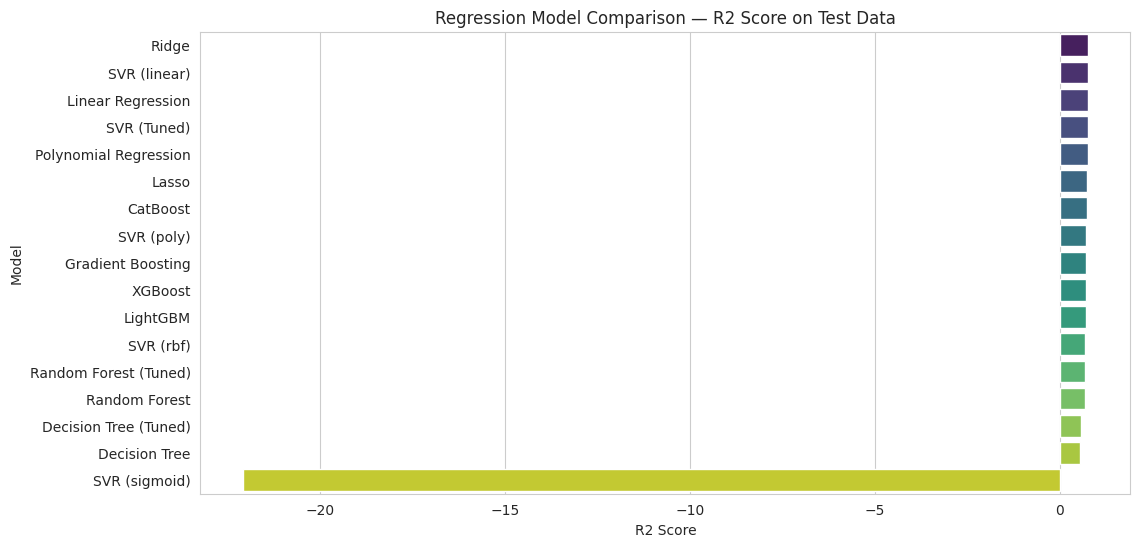

Best performing model: Ridge


In [23]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results_df, x='R2_Test', y='Model', palette='viridis')
plt.title('Regression Model Comparison — R2 Score on Test Data')
plt.xlabel('R2 Score')
plt.show()
print("Best performing model:", results_df.iloc[0]['Model'])


## Step 16: Dropout-Risk Label (Proxy) + Classification Model
Is dataset me directly "dropout" column nahi hai, is liye hum ek **evidence-based proxy label** bana rahe hain:
Student ko **"At Risk"** mana jayega agar uski **Attendance kam (<70%)**, **Exam_Score kam (bottom 25%)**, aur **Motivation_Level Low** ho.
Yeh label 100% real dropout data nahi, balke ek **risk-indicator** hai jo real institutional dropout records milne par retrain ho sakta hai.


In [24]:
score_25th = df_raw['Exam_Score'].quantile(0.25)

at_risk = (
    (df_raw['Attendance'] < 70) &
    (df_raw['Exam_Score'] <= score_25th) &
    (df_raw['Motivation_Level'] == 'Low')
).astype(int)

df['At_Risk'] = at_risk
df_raw['At_Risk'] = at_risk

print("At-Risk students:", df['At_Risk'].sum(), "out of", len(df))
print("At-Risk rate:", round(df['At_Risk'].mean()*100, 2), "%")


At-Risk students: 364 out of 6607
At-Risk rate: 5.51 %


              precision    recall  f1-score   support

           0       1.00      0.99      1.00      1249
           1       0.91      1.00      0.95        73

    accuracy                           0.99      1322
   macro avg       0.96      1.00      0.98      1322
weighted avg       1.00      0.99      0.99      1322

ROC-AUC: 0.999


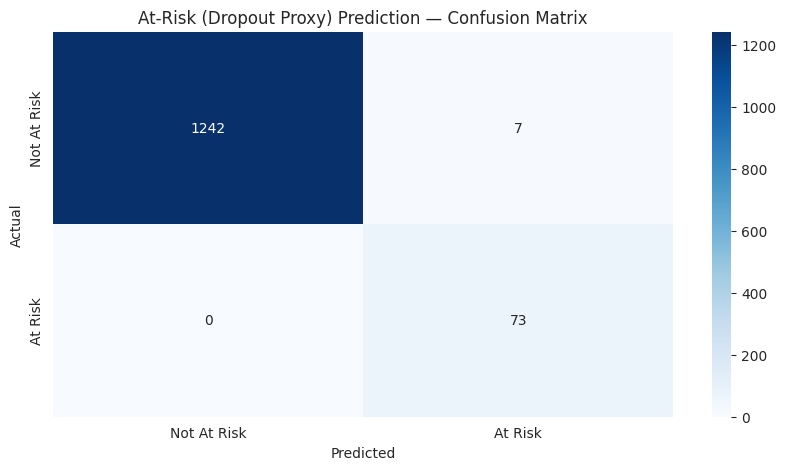

In [25]:
Xc = df.drop(['Exam_Score', 'At_Risk'], axis=1)
yc = df['At_Risk']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)

scaler = StandardScaler()
Xc_train_s = scaler.fit_transform(Xc_train)
Xc_test_s = scaler.transform(Xc_test)

clf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42, class_weight='balanced')
clf.fit(Xc_train_s, yc_train)

pred = clf.predict(Xc_test_s)
proba = clf.predict_proba(Xc_test_s)[:, 1]

print(classification_report(yc_test, pred))
print("ROC-AUC:", round(roc_auc_score(yc_test, proba), 3))

cm = confusion_matrix(yc_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not At Risk','At Risk'], yticklabels=['Not At Risk','At Risk'])
plt.title('At-Risk (Dropout Proxy) Prediction — Confusion Matrix')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.show()


In [26]:
importances = pd.Series(clf.feature_importances_, index=Xc.columns).sort_values(ascending=False).head(10)
fig = px.bar(importances, orientation='h', title='Top Features Driving At-Risk / Dropout Prediction')
fig.show()


## Step 17: Anomaly Detection
SRS requirement: unusual patterns detect karna (e.g. bohot kam study hours ke bawajood high score, ya high attendance ke bawajood bohot kam score).


In [27]:
iso_features = ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Exam_Score']
iso = IsolationForest(contamination=0.05, random_state=42)
df_raw['Anomaly'] = iso.fit_predict(df_raw[iso_features])
df_raw['Anomaly'] = df_raw['Anomaly'].map({1: 'Normal', -1: 'Anomaly'})

print(df_raw['Anomaly'].value_counts())

fig = px.scatter(df_raw, x='Attendance', y='Exam_Score', color='Anomaly',
                  title='Anomaly Detection — Attendance vs Exam Score',
                  color_discrete_map={'Normal': '#2E86AB', 'Anomaly': '#E63946'}, opacity=0.6)
fig.show()


Anomaly
Normal     6276
Anomaly     331
Name: count, dtype: int64


## Step 18: Trend Analysis
SRS requirement: patterns/trends dikhana. Hum dekhte hain ke **Hours_Studied badhne se Exam_Score kaise trend karta hai** (binned average) — yeh ek practical trend-analysis view hai jo asal dataset se seedha nikalta hai.


In [28]:
trend_df = df_raw.groupby(pd.cut(df_raw['Hours_Studied'], bins=10))['Exam_Score'].mean().reset_index()
trend_df['Hours_Studied'] = trend_df['Hours_Studied'].astype(str)

fig = go.Figure()
fig.add_trace(go.Scatter(x=trend_df['Hours_Studied'], y=trend_df['Exam_Score'],
                          mode='lines+markers', name='Avg Exam Score'))
fig.update_layout(title='Trend: Hours Studied vs Average Exam Score', xaxis_title='Hours Studied (binned)',
                   yaxis_title='Average Exam Score')
fig.show()


## Step 19: Interactive Dashboard
SRS requirement: stakeholders ke liye customizable, interactive dashboard.


In [30]:
fig = make_subplots(rows=2, cols=2, subplot_titles=(
    'At-Risk Rate by Family Income', 'Avg Exam Score by School Type',
    'Attendance vs Exam Score', 'At-Risk Distribution'),
    specs=[[{}, {}], [{}, {'type': 'domain'}]])

d1 = df_raw.groupby('Family_Income')['At_Risk'].mean().reset_index()
fig.add_trace(go.Bar(x=d1['Family_Income'], y=d1['At_Risk'], name='At-Risk Rate'), row=1, col=1)

d2 = df_raw.groupby('School_Type')['Exam_Score'].mean().reset_index()
fig.add_trace(go.Bar(x=d2['School_Type'], y=d2['Exam_Score'], name='Avg Score'), row=1, col=2)

fig.add_trace(go.Scatter(x=df_raw['Attendance'], y=df_raw['Exam_Score'], mode='markers',
                          marker=dict(size=4, opacity=0.4), name='Students'), row=2, col=1)

d4 = df_raw['At_Risk'].value_counts().reset_index()
d4.columns = ['At_Risk', 'count']
fig.add_trace(go.Pie(labels=['Not At Risk', 'At Risk'], values=d4['count']), row=2, col=2)

fig.update_layout(height=800, width=1000, title_text='EduPredict — Key Metrics Dashboard', showlegend=False)
fig.show()

## Step 20: Automated Alerts / Notifications
SRS requirement: predefined thresholds ke basis pe alerts generate karna.


In [31]:
ALERT_ATTENDANCE_THRESHOLD = 65
ALERT_RISK_PROB_THRESHOLD = 0.6

df_raw['Risk_Probability'] = clf.predict_proba(scaler.transform(Xc))[:, 1]

alerts = df_raw[(df_raw['Attendance'] < ALERT_ATTENDANCE_THRESHOLD) |
                (df_raw['Risk_Probability'] > ALERT_RISK_PROB_THRESHOLD)]

print(f"Total students needing intervention alert: {len(alerts)}")
for idx, row in alerts.head(10).iterrows():
    print(f"ALERT -> Student #{idx}: attendance={row['Attendance']}%, "
          f"risk_probability={round(row['Risk_Probability'],2)} -> Notify advisor/teacher")


Total students needing intervention alert: 933
ALERT -> Student #1: attendance=64%, risk_probability=0.93 -> Notify advisor/teacher
ALERT -> Student #16: attendance=60%, risk_probability=0.92 -> Notify advisor/teacher
ALERT -> Student #25: attendance=62%, risk_probability=0.12 -> Notify advisor/teacher
ALERT -> Student #29: attendance=66%, risk_probability=0.91 -> Notify advisor/teacher
ALERT -> Student #33: attendance=60%, risk_probability=0.12 -> Notify advisor/teacher
ALERT -> Student #36: attendance=65%, risk_probability=0.92 -> Notify advisor/teacher
ALERT -> Student #39: attendance=65%, risk_probability=0.9 -> Notify advisor/teacher
ALERT -> Student #42: attendance=63%, risk_probability=0.16 -> Notify advisor/teacher
ALERT -> Student #47: attendance=61%, risk_probability=0.13 -> Notify advisor/teacher
ALERT -> Student #61: attendance=65%, risk_probability=0.91 -> Notify advisor/teacher


## Step 21: Save Models & Processed Data

In [32]:
import pickle, os

os.makedirs('/content/models', exist_ok=True)
with open('/content/models/exam_score_model.pkl', 'wb') as f:
    pickle.dump(best_rf, f)
with open('/content/models/at_risk_model.pkl', 'wb') as f:
    pickle.dump(clf, f)
with open('/content/models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

results_df.to_csv('/content/regression_model_comparison.csv', index=False)
df_raw.to_csv('/content/edupredict_processed_data.csv', index=False)

print("All models & processed data saved in /content/")


All models & processed data saved in /content/


In [33]:
import pickle, os
from google.colab import drive

# Google Drive mount karna
drive.mount('/content/drive')

# Save karne ke liye Drive folder path setup
drive_path = '/content/drive/MyDrive/Ai_PrimerCourse/ColabDataSet'
models_dir = os.path.join(drive_path, 'models')
os.makedirs(models_dir, exist_ok=True)

# Models save karna
with open(os.path.join(models_dir, 'exam_score_model.pkl'), 'wb') as f:
    pickle.dump(best_rf, f)

with open(os.path.join(models_dir, 'at_risk_model.pkl'), 'wb') as f:
    pickle.dump(clf, f)

with open(os.path.join(models_dir, 'scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)

# Datasets save karna
results_df.to_csv(os.path.join(drive_path, 'regression_model_comparison.csv'), index=False)
df_raw.to_csv(os.path.join(drive_path, 'edupredict_processed_data.csv'), index=False)

print("All models & processed data saved successfully in Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All models & processed data saved successfully in Google Drive!
